In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import Xception
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report

2026-03-31 17:43:09.116390: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774978989.723057      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774978989.840538      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774978990.847736      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774978990.847778      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774978990.847781      23 computation_placer.cc:177] computation placer alr

In [2]:
base_dir = '/kaggle/input/datasets/ibibekkumar/autism-dataset/Autism Dataset'

train_dir = os.path.join(base_dir, 'train')
valid_dir = os.path.join(base_dir, 'valid')
test_dir  = os.path.join(base_dir, 'test')

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    train_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

valid_data = val_test_datagen.flow_from_directory(
    valid_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

test_data = val_test_datagen.flow_from_directory(
    test_dir, target_size=(224,224), batch_size=32,
    class_mode='binary', shuffle=False
)

Found 2386 images belonging to 2 classes.
Found 254 images belonging to 2 classes.
Found 300 images belonging to 2 classes.


In [4]:
def build_xception_model():
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output)

tf.keras.backend.clear_session()
model = build_xception_model()
model.summary()

I0000 00:00:1774979037.228385      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774979037.234404      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 111, 111,  │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 111, 111,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 111, 111,  │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 109, 109,  │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 109, 109,  │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 109, 109,  │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 109, 109,  │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 109, 109,  │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 109, 109,  │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 109, 109,  │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 109, 109,  │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 55, 55,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 55, 55,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 55, 55,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 55, 55,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 55, 55,    │          0 │ add[0][0]       

 Total params: 21,394,473 (81.61 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 20,865,576 (79.60 MB)

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7)
]

In [6]:
print("\n--- Phase 1: Training Top Layers ---")

history1 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=15,
    callbacks=callbacks
)


--- Phase 1: Training Top Layers ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15


I0000 00:00:1774979047.197323      90 service.cc:152] XLA service 0x7c484403ecb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774979047.197359      90 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774979047.197363      90 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774979048.537426      90 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-03-31 17:44:18.536327: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:44:18.717517: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:44:20.698646: E external/local_xl

57/75 ━━━━━━━━━━━━━━━━━━━━ 10s 565ms/step - accuracy: 0.5639 - loss: 0.8261

2026-03-31 17:45:06.537598: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:06.696059: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:07.898569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:08.034970: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:09.003545: E external/local_xla/xla/stream_

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 738ms/step - accuracy: 0.5743 - loss: 0.8145

2026-03-31 17:45:36.524601: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:36.705216: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:38.679834: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:38.819136: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:45:40.031974: E external/local_xla/xla/stream_

75/75 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.5748 - loss: 0.8140 - val_accuracy: 0.7323 - val_loss: 0.5866 - learning_rate: 1.0000e-04
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 430ms/step - accuracy: 0.6516 - loss: 0.7068 - val_accuracy: 0.7953 - val_loss: 0.5304 - learning_rate: 1.0000e-04
Epoch 3/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 423ms/step - accuracy: 0.6925 - loss: 0.6385 - val_accuracy: 0.7913 - val_loss: 0.4929 - learning_rate: 1.0000e-04
Epoch 4/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 426ms/step - accuracy: 0.6907 - loss: 0.6346 - val_accuracy: 0.8071 - val_loss: 0.4696 - learning_rate: 1.0000e-04
Epoch 5/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 429ms/step - accuracy: 0.6957 - loss: 0.6369 - val_accuracy: 0.7953 - val_loss: 0.4526 - learning_rate: 1.0000e-04
Epoch 6/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 431ms/step - accuracy: 0.6977 - loss: 0.6066 - val_accuracy: 0.8150 - val_loss: 0.4537 - learning_rate: 1.0000e-04
Epoch 7/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 424ms/step - accuracy: 0.7111

In [7]:
# Unfreeze last 70 layers (Xception benefits from deeper tuning)
for layer in model.layers[-70:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("\n--- Phase 2: Fine-Tuning Xception ---")

history2 = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=10,
    callbacks=callbacks
)


--- Phase 2: Fine-Tuning Xception ---
Epoch 1/10


2026-03-31 17:53:30.976369: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:53:31.118322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


45/75 ━━━━━━━━━━━━━━━━━━━━ 12s 432ms/step - accuracy: 0.7268 - loss: 0.5658

2026-03-31 17:53:59.375108: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:53:59.511754: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


75/75 ━━━━━━━━━━━━━━━━━━━━ 67s 652ms/step - accuracy: 0.7354 - loss: 0.5511 - val_accuracy: 0.8150 - val_loss: 0.4359 - learning_rate: 1.0000e-05
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 433ms/step - accuracy: 0.7460 - loss: 0.5141 - val_accuracy: 0.8189 - val_loss: 0.4416 - learning_rate: 1.0000e-05
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 431ms/step - accuracy: 0.7767 - loss: 0.4797 - val_accuracy: 0.8346 - val_loss: 0.4352 - learning_rate: 1.0000e-05
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 35s 461ms/step - accuracy: 0.7919 - loss: 0.4644 - val_accuracy: 0.8228 - val_loss: 0.4286 - learning_rate: 1.0000e-05
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 430ms/step - accuracy: 0.7998 - loss: 0.4446 - val_accuracy: 0.8307 - val_loss: 0.4157 - learning_rate: 1.0000e-05
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 435ms/step - accuracy: 0.8030 - loss: 0.4393 - val_accuracy: 0.8465 - val_loss: 0.4022 - learning_rate: 1.0000e-05
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 433ms/step - accuracy: 0.79

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step

2026-03-31 17:59:36.933469: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:59:37.081381: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:59:38.186880: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:59:38.321384: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-31 17:59:39.193501: E external/local_xla/xla/stream_

10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step


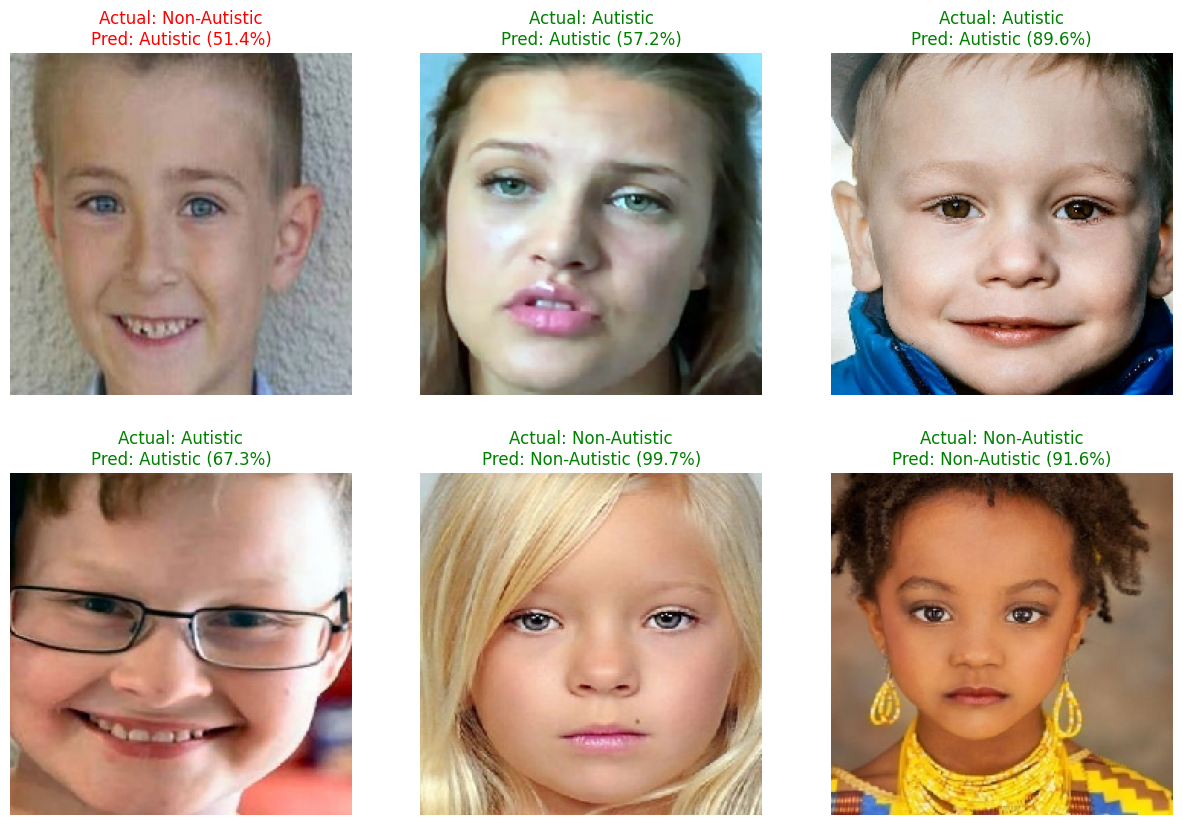

In [8]:
test_data.reset()
predictions = model.predict(test_data)

y_pred = (predictions > 0.5).astype(int).flatten()
y_true = test_data.classes

labels = {v: k for k, v in test_data.class_indices.items()}

plt.figure(figsize=(15, 10))

for i in range(6):
    idx = np.random.randint(0, len(test_data.filenames))

    img_path = os.path.join(test_dir, test_data.filenames[idx])
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224,224))

    plt.subplot(2, 3, i+1)
    plt.imshow(img)

    actual = labels[y_true[idx]]
    pred = labels[y_pred[idx]]

    conf = predictions[idx][0] if y_pred[idx] == 1 else 1 - predictions[idx][0]
    color = 'green' if actual == pred else 'red'

    plt.title(f"Actual: {actual}\nPred: {pred} ({conf*100:.1f}%)", color=color)
    plt.axis('off')

plt.show()

In [9]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=list(labels.values())
))


Classification Report:

              precision    recall  f1-score   support

    Autistic       0.77      0.91      0.83       150
Non-Autistic       0.89      0.73      0.80       150

    accuracy                           0.82       300
   macro avg       0.83      0.82      0.82       300
weighted avg       0.83      0.82      0.82       300



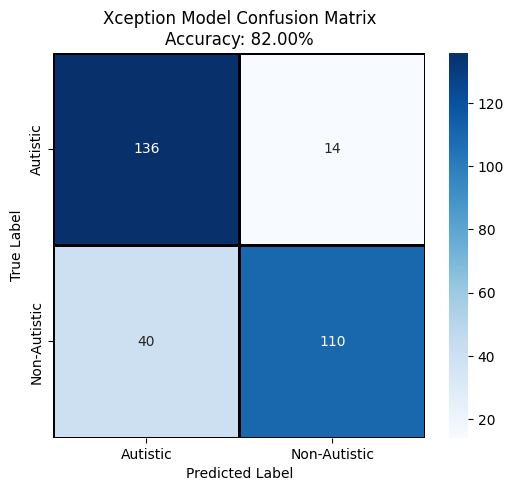

In [10]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Accuracy
accuracy = np.mean(y_pred == y_true)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=list(labels.values()),
    yticklabels=list(labels.values()),
    linewidths=1,
    linecolor='black'
)

plt.title(f'Xception Model Confusion Matrix\nAccuracy: {accuracy*100:.2f}%')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

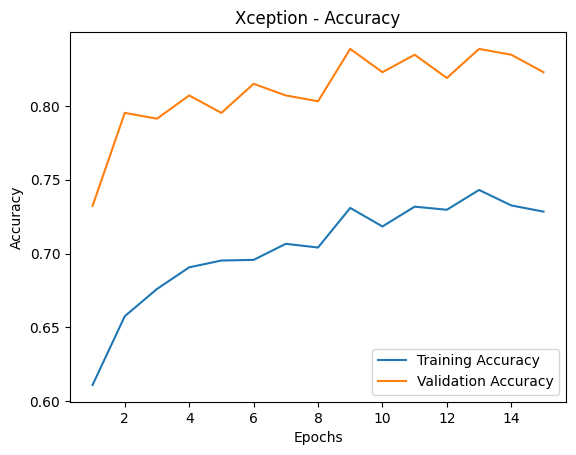

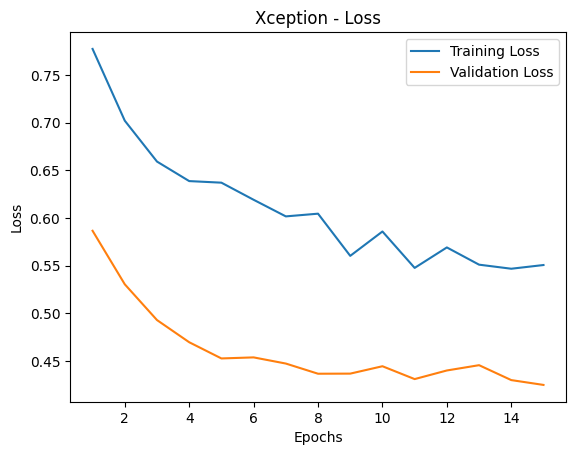

In [11]:
import matplotlib.pyplot as plt

acc = history1.history['accuracy']
val_acc = history1.history['val_accuracy']

loss = history1.history['loss']
val_loss = history1.history['val_loss']

epochs = range(1, len(acc) + 1)

# Accuracy Graph
plt.figure()
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Xception - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss Graph
plt.figure()
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Xception - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [12]:
model.save('xception_autism_model.h5')